# **ML-Assignment 4**

**Import libraries and load dataset**

In [2]:
%pip -q install kagglehub

import kagglehub
import glob, os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score
)

path = kagglehub.dataset_download("abdallamahgoub/diabetes")

df = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])

print(df.head())
print("Dataset shape:", df.shape)

100%|██████████| 8.89k/8.89k [00:00<00:00, 20.8MB/s]

Extracting files...
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  
Dataset shape: (768, 9)


**Preprocess data and check outliers**

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


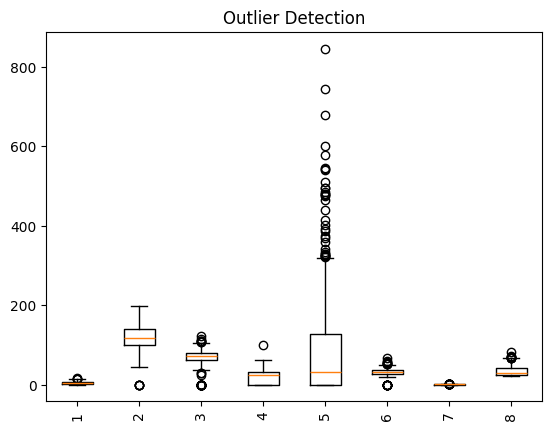

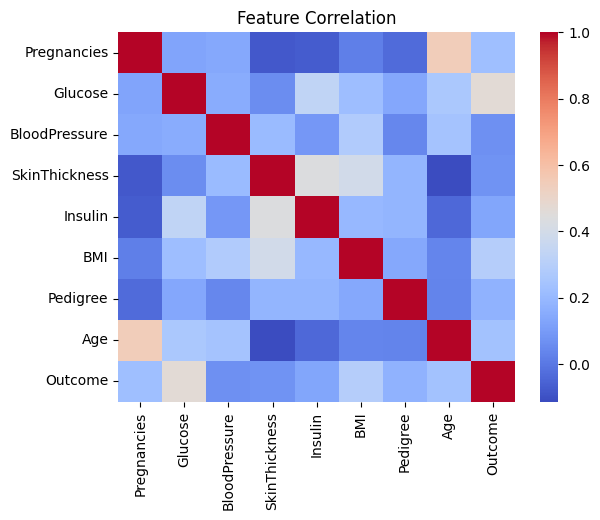

In [3]:
print(df.isnull().sum())

# Visualize outliers
plt.boxplot(df.drop(columns="Outcome"))
plt.title("Outlier Detection")
plt.xticks(rotation=90)
plt.show()

# Check correlation
sns.heatmap(df.corr(), cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

**Split and scale the data**

In [4]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Train the KNN model**

In [5]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

pred = knn.predict(X_test)
print("KNN model trained successfully!")

KNN model trained successfully!


**Evaluate the model**

In [6]:
cm = confusion_matrix(y_test, pred)

print("Confusion Matrix:\n", cm)
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("Error Rate:", round(1 - accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, pred, zero_division=0), 3))

Confusion Matrix:
 [[80 20]
 [26 28]]
Accuracy: 0.701
Error Rate: 0.299
Precision: 0.583
Recall: 0.519
